# EDA

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

Load Dataset

In [13]:
df = pd.read_csv('../data/online_shoppers_intention.csv')
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Initial Data Exploration

In [17]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [18]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [23]:
# check the dataset dimensions
df.shape

(12330, 18)

The result shows that the dataset contains 12,330 online browsing sessions, with 17 features and 1 target variable.

Data Quality Assessment

In [19]:
# check for missing values
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

The results indicate that there are no missing values in our online shoppers dataset.

In [22]:
# check for duplicates
df.duplicated().sum()

np.int64(125)

The result indicates that there are 125 duplicate rows in our online shoppers dataset. Further investigation is needed to determine whether any of these duplicate rows should be removed.

# Data Cleaning/Preparation

### Investigating duplicate rows

Since there are 125 duplicate rows, we will investigate these rows to determine whether they should be removed.

In [33]:
duplicate = df[df.duplicated()]
duplicate.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,125.0,125.0,125.0,125.0,125.000000,125.0,125.0,125.0,125.0,125.000000,125.000000,125.000000,125.000000,125.000000
mean,0.0,0.0,0.0,0.0,1.056000,0.0,0.2,0.2,0.0,0.011200,2.104000,2.288000,2.568000,3.648000
std,0.0,0.0,0.0,0.0,0.230847,0.0,0.0,0.0,0.0,0.089096,1.281531,2.320373,2.262371,4.784478
min,0.0,0.0,0.0,0.0,1.000000,0.0,0.2,0.2,0.0,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.0,0.0,0.0,0.0,1.000000,0.0,0.2,0.2,0.0,0.000000,1.000000,1.000000,1.000000,1.000000
50%,0.0,0.0,0.0,0.0,1.000000,0.0,0.2,0.2,0.0,0.000000,2.000000,2.000000,1.000000,1.000000
75%,0.0,0.0,0.0,0.0,1.000000,0.0,0.2,0.2,0.0,0.000000,2.000000,2.000000,3.000000,3.000000
max,0.0,0.0,0.0,0.0,2.000000,0.0,0.2,0.2,0.0,0.800000,8.000000,13.000000,9.000000,20.000000


The results show that all 125 duplicate rows have zero values for 'Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', and 'ProductRelated_Duration'. However, the visitors accessed one or two product-related pages. This could indicate that the visitors were not on the website long enough for their browsing duration to be recorded.

In [34]:
duplicate['Revenue'].value_counts()

Revenue
False    125
Name: count, dtype: int64

The result shows 125 values of False, meaning that none of these browsing sessions resulted in a purchase.

In conclusion, we will not remove the duplicate rows because they could represent different visitors with similar browsing behaviors.

### Investigating zero values

Looking at the features "Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated", and "ProductRelated_Duration", we can determine the number of pages visited in each category during a browsing session, as well as the total time spent. 

In [28]:
df[['Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration']]

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration
0,0,0.0,0,0.0,1,0.000000
1,0,0.0,0,0.0,2,64.000000
2,0,0.0,0,0.0,1,0.000000
3,0,0.0,0,0.0,2,2.666667
4,0,0.0,0,0.0,10,627.500000
...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667
12326,0,0.0,0,0.0,5,465.750000
12327,0,0.0,0,0.0,6,184.250000
12328,4,75.0,0,0.0,15,346.000000


In [ ]:
(df['Informational_Duration'] == 0).sum()

np.int64(9925)

In [31]:
(df['Informational'] == 0).sum()

np.int64(9699)

In [35]:
(df['Administrative']==0).sum()

np.int64(5768)

In [36]:
(df['Administrative_Duration']==0).sum()

np.int64(5903)

In [37]:
(df['ProductRelated']==0).sum()

np.int64(38)

In [38]:
(df['ProductRelated_Duration']==0).sum()

np.int64(755)

The result for 'Informational_Duration' shows that there are 9,925 rows with zero values out of 12,330 rows. The result for 'Informational' shows 9,699 rows with zero values out of 12,330 rows. The result for 'Administrative' shows 5,768 rows with zero values out of 12,330 rows. The result for 'Administrative_Duration' shows 5,903 rows with zero values out of 12,330 rows. The result for 'ProductRelated' shows 38 rows with zero values out of 12,330 rows. The result for 'ProductRelated_Duration' shows 755 rows with zero values out of 12,330 rows. Removing these features might not benefit our analysis. These features would have been removed if all values in their respective columns were zero. Therefore, we will retain all six features for now.

### Investigating categorical features

In [ ]:
# Check the unique values for each feature
df.nunique()

Administrative               27
Administrative_Duration    3335
Informational                17
Informational_Duration     1258
ProductRelated              311
ProductRelated_Duration    9551
BounceRates                1872
ExitRates                  4777
PageValues                 2704
SpecialDay                    6
Month                        10
OperatingSystems              8
Browser                      13
Region                        9
TrafficType                  20
VisitorType                   3
Weekend                       2
Revenue                       2
dtype: int64

Looking at the results, I noticed that 'Weekend' and 'Revenue' each have to unique values because they are binary categorical variables.

### Check for potential outlier

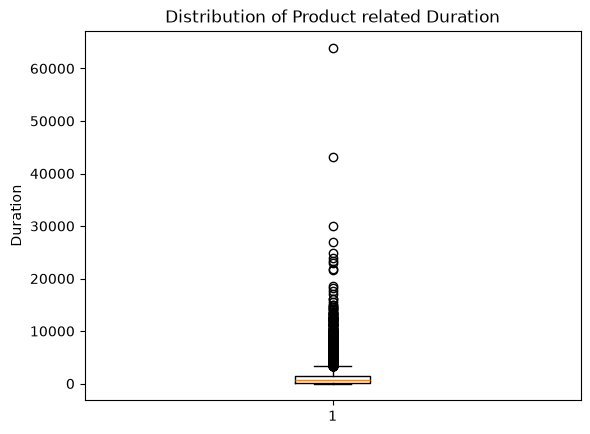

In [ ]:
plt.boxplot(df['ProductRelated_Duration'])
plt.title('Distribution of Product-related Duration')
plt.ylabel('Duration')
plt.show()